### Import Libraries

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

### 1. Loading Dataset

In [3]:
claimants_data = pd.read_csv('claimants.csv')
claimants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


### 2. Data Understanding - Exploration

In [4]:
claimants_data.shape

(1340, 7)

In [5]:
claimants_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [6]:
claimants_data.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [7]:
claimants_data.duplicated().sum()

0

In [8]:
claimants_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


### 3. Data Preparation

In [9]:
## Drop null values
claimants_cleaned = claimants_data.dropna()
claimants_cleaned

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


X / Y - Split

In [10]:
X = claimants_cleaned[['CLMSEX','CLMINSUR','SEATBELT','CLMAGE','LOSS']]
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [11]:
y = claimants_cleaned['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

### 4. Model Building - Building Decision Tree

In [12]:
## Building Decision Tree

In [13]:
dt_model = DecisionTreeClassifier()

Train / Test Split

In [14]:
x_train, x_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=32, shuffle=True)
x_train, x_test, y_train, y_test

(      CLMSEX  CLMINSUR  SEATBELT  CLMAGE    LOSS
 963      1.0       1.0       0.0     6.0   0.608
 615      1.0       1.0       0.0     0.0   0.407
 74       0.0       1.0       0.0     0.0   0.445
 543      0.0       1.0       0.0    44.0   3.666
 287      1.0       1.0       0.0    19.0  68.560
 ...      ...       ...       ...     ...     ...
 625      1.0       1.0       0.0    71.0   8.708
 305      0.0       1.0       0.0    33.0   0.886
 107      1.0       0.0       0.0    10.0   3.975
 1091     0.0       0.0       0.0    47.0   6.070
 895      0.0       1.0       0.0    16.0   1.800
 
 [876 rows x 5 columns],
       CLMSEX  CLMINSUR  SEATBELT  CLMAGE   LOSS
 1035     0.0       1.0       0.0    10.0  0.663
 1255     0.0       1.0       0.0    48.0  0.455
 347      1.0       1.0       0.0    56.0  3.009
 121      1.0       1.0       0.0     9.0  5.813
 511      1.0       1.0       0.0     8.0  3.086
 ...      ...       ...       ...     ...    ...
 354      1.0       0.0       

### 5. Model Training

In [15]:
dt_model.fit(X=x_train, y=y_train)

DecisionTreeClassifier()

### 6. Model Testing

In [16]:
# Testing with Train/Test Data

y_pred_train = dt_model.predict(x_train)

y_pred_test = dt_model.predict(x_test)

### 7. Model Evaluation

Training Data - Evaluation

[[471   0]
 [  3 402]]


<Axes: >

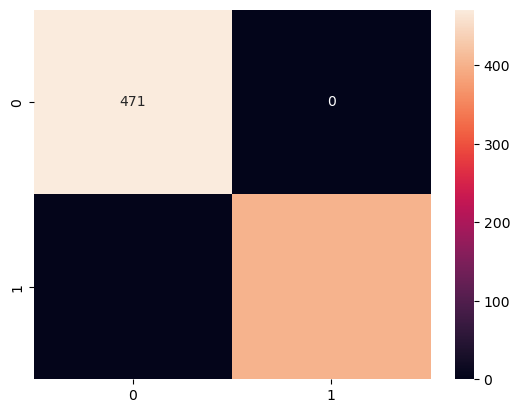

In [17]:
print(confusion_matrix(y_true=y_train, y_pred=y_pred_train))
sns.heatmap(confusion_matrix(y_true=y_train, y_pred=y_pred_train), annot=True, fmt='')

In [18]:
print(classification_report(y_true=y_train, y_pred=y_pred_train))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       471
           1       1.00      0.99      1.00       405

    accuracy                           1.00       876
   macro avg       1.00      1.00      1.00       876
weighted avg       1.00      1.00      1.00       876



ROC AUC Score: 0.9963


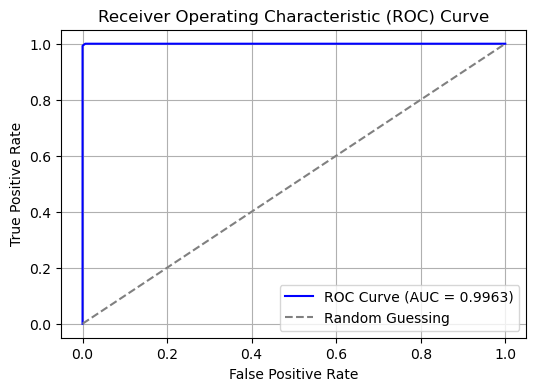

In [19]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_train, y_pred_train)
print(f"ROC AUC Score: {auc_score:.4f}")

# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_train, dt_model.predict_proba(x_train)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

TESTING DATA - EVALUATION

[[69 38]
 [53 60]]


<Axes: >

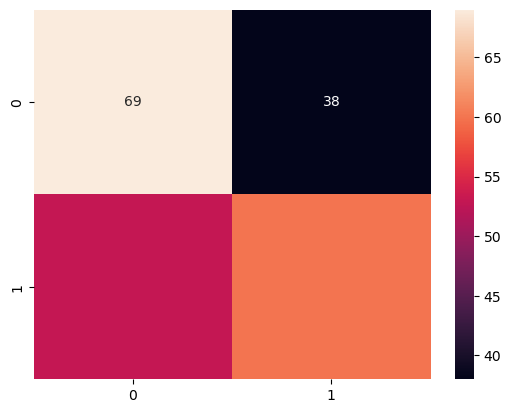

In [20]:
print(confusion_matrix(y_true=y_test, y_pred=y_pred_test))
sns.heatmap(confusion_matrix(y_true=y_test, y_pred=y_pred_test), annot=True, fmt='')

In [21]:
print(classification_report(y_true=y_test, y_pred=y_pred_test))

              precision    recall  f1-score   support

           0       0.57      0.64      0.60       107
           1       0.61      0.53      0.57       113

    accuracy                           0.59       220
   macro avg       0.59      0.59      0.59       220
weighted avg       0.59      0.59      0.59       220



ROC AUC Score: 0.5879


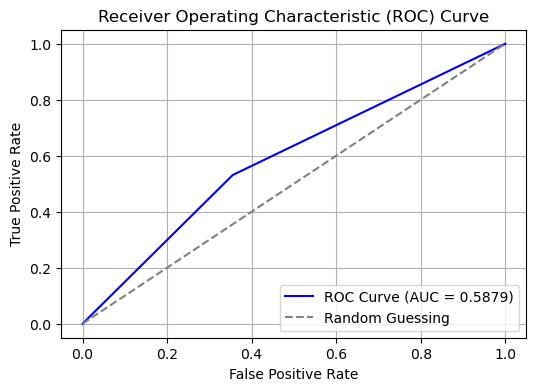

In [22]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_test)
print(f"ROC AUC Score: {auc_score:.4f}")

# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test, dt_model.predict_proba(x_test)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Visualisation - Decision Tree (Version 1)

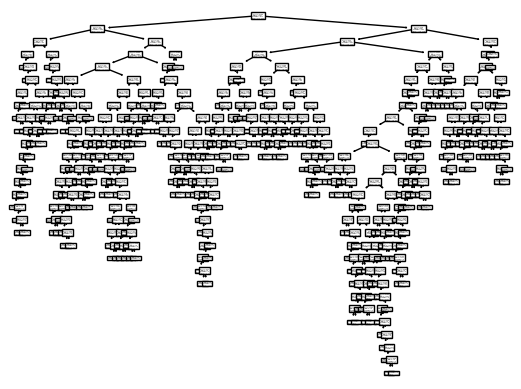

In [23]:
plot_tree(decision_tree=dt_model)
plt.show()

## Decision Tree - Version 2

### Hyper Parameter Tuning

In [25]:
grid_search = GridSearchCV (
                estimator = dt_model,
                param_grid = {'criterion':["gini", "entropy", "log_loss"],
                                'max_depth':[3,5,7,9]}
            )

In [26]:
grid_search.fit(x_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [3, 5, 7, 9]})

In [29]:
grid_search.best_estimator_

DecisionTreeClassifier(criterion='entropy', max_depth=5)

In [30]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'criterion': 'entropy', 'max_depth': 5}
0.7260324675324676


In [33]:
dt_model2 = DecisionTreeClassifier(criterion='entropy', max_depth=5)
dt_model2.fit(X=x_train, y=y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=5)

### Evaluation - Decition Tree Version 2

Training Data - Evaluation

In [34]:
y_pred_train2 = dt_model2.predict(x_train)

[[370 101]
 [113 292]]


<Axes: >

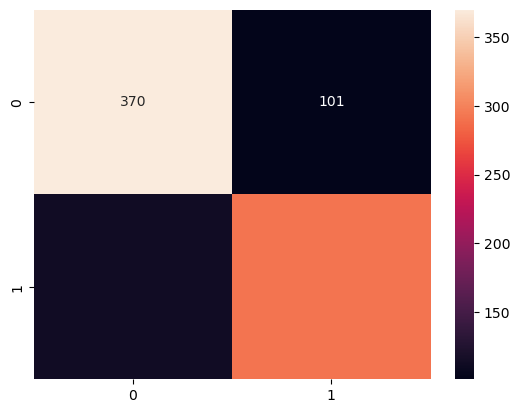

In [39]:
print(confusion_matrix(y_true=y_train, y_pred=y_pred_train2))
sns.heatmap(confusion_matrix(y_true=y_train, y_pred=y_pred_train2), annot=True, fmt='')

In [40]:
print(classification_report(y_true=y_train, y_pred=y_pred_train2))


              precision    recall  f1-score   support

           0       0.77      0.79      0.78       471
           1       0.74      0.72      0.73       405

    accuracy                           0.76       876
   macro avg       0.75      0.75      0.75       876
weighted avg       0.76      0.76      0.76       876



ROC AUC Score: 0.7533


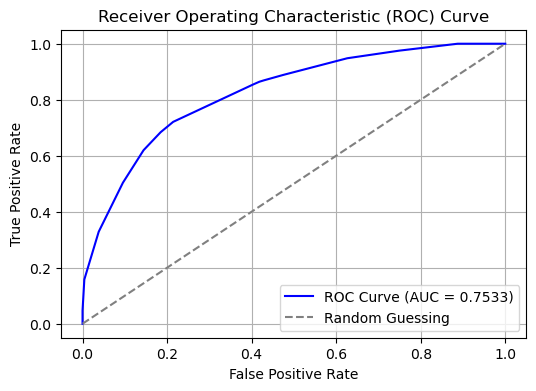

In [41]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_train, y_pred_train2)
print(f"ROC AUC Score: {auc_score:.4f}")

# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_train, dt_model2.predict_proba(x_train)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Testing Data - Evaluation

In [43]:
y_pred_test2 = dt_model2.predict(x_test)

[[71 36]
 [33 80]]


<Axes: >

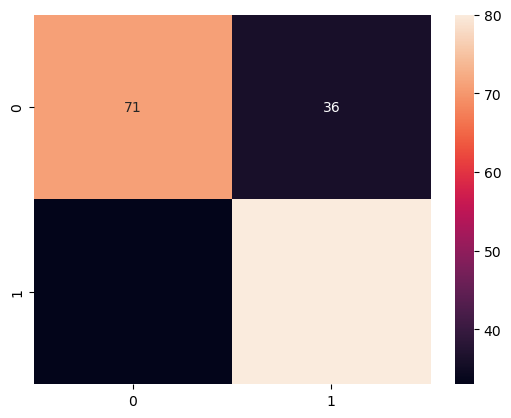

In [44]:
print(confusion_matrix(y_true=y_test, y_pred=y_pred_test2))
sns.heatmap(confusion_matrix(y_true=y_test, y_pred=y_pred_test2), annot=True, fmt='')

In [45]:
print(classification_report(y_true=y_test, y_pred=y_pred_test2))


              precision    recall  f1-score   support

           0       0.68      0.66      0.67       107
           1       0.69      0.71      0.70       113

    accuracy                           0.69       220
   macro avg       0.69      0.69      0.69       220
weighted avg       0.69      0.69      0.69       220



ROC AUC Score: 0.6858


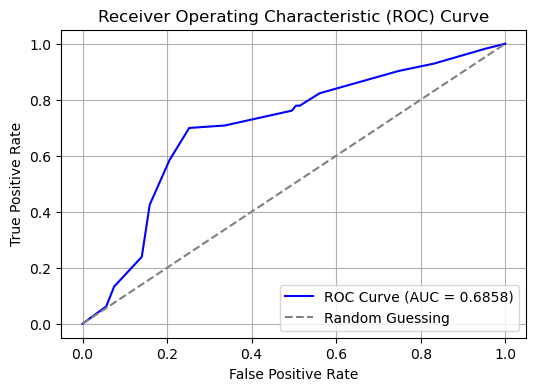

In [46]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_test2)
print(f"ROC AUC Score: {auc_score:.4f}")

# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test, dt_model2.predict_proba(x_test)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()